# Training panel exploration

This notebook only looks at `training_panel_2021.csv`. No model.

Each row is one **New Jersey workplace** on one day of 2021. The first three days of the year are already removed, because velocity, acceleration, and jerk need earlier days. There are no blank cells.

| Column | Meaning |
|---|---|
| `zipcode` | Workplace ZCTA |
| `date` | Day |
| `day_of_week` | Monday = 0 through Sunday = 6 |
| `daily_cases` | Cases reported in that workplace ZCTA |
| `velocity` | Today's cases minus yesterday's |
| `acceleration` | Today's velocity minus yesterday's |
| `jerk` | Today's acceleration minus yesterday's |
| `pressure` | Commute-weighted cases flowing **in** from other NJ ZCTAs and NYC |
| `weight_coverage` | Share of inbound commute weights that had a case count (1 in this file) |

Run from the project root, or from this folder. The loader checks both.


## 1. Load

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

path = Path("training_panel_2021.csv")
if not path.exists():
    path = Path("Dhruvesh/training/training_panel_2021.csv")

panel = pd.read_csv(path, dtype={"zipcode": str}, parse_dates=["date"])
panel["zipcode"] = panel["zipcode"].str.zfill(5)
panel = panel.sort_values(["zipcode", "date"]).reset_index(drop=True)

print(path.resolve())
print(f"{panel.shape[0]:,} rows  x  {panel.shape[1]} columns")
print(f"{panel.zipcode.nunique()} workplaces   {panel.date.min().date()} to {panel.date.max().date()}")
panel.head()


/Users/dhruvesh/Desktop/Fall 2026/Analytics/Jupyter/Dhruvesh/training/training_panel_2021.csv
213,580 rows  x  9 columns
590 workplaces   2021-01-04 to 2021-12-31


,zipcode,date,day_of_week,daily_cases,velocity,acceleration,jerk,pressure,weight_coverage
0,07001,2021-01-04,0,29,24.0,36.0,55.0,27.015162,1.0
1,07001,2021-01-05,1,18,-11.0,-35.0,-71.0,26.767210,1.0
2,07001,2021-01-06,2,10,-8.0,3.0,38.0,25.816932,1.0
3,07001,2021-01-07,3,14,4.0,12.0,9.0,29.579339,1.0
4,07001,2021-01-08,4,23,9.0,5.0,-7.0,25.146812,1.0


## 2. Summary stats

`describe` is the quick picture: typical value, spread, smallest, largest.

`daily_cases` and `pressure` stay at or above zero. `velocity`, `acceleration`, and `jerk` can be negative, because they are changes: a negative velocity means cases fell from yesterday.


In [2]:
panel.describe().round(2)


,date,day_of_week,daily_cases,velocity,acceleration,jerk,pressure,weight_coverage
count,213580,213580.00,213580.00,213580.00,213580.00,213580.00,213580.00,213580.0
mean,2021-07-03 11:59:59.999999,2.99,3.46,0.02,-0.00,0.00,6.18,1.0
min,2021-01-04 00:00:00,0.00,0.00,-513.00,-1043.00,-1561.00,0.00,1.0
25%,2021-04-04 00:00:00,1.00,0.00,-1.00,-2.00,-3.00,1.07,1.0
50%,2021-07-03 12:00:00,3.00,1.00,0.00,0.00,0.00,2.29,1.0
75%,2021-10-02 00:00:00,5.00,3.00,1.00,2.00,3.00,8.26,1.0
max,2021-12-31 00:00:00,6.00,646.00,530.00,617.00,1660.00,79.25,1.0
std,NaN,2.00,8.41,6.43,11.03,20.04,7.79,0.0


In [3]:
print("Blank cells:", int(panel.isna().sum().sum()))
print("First date:", panel.date.min().date(), "  Last date:", panel.date.max().date())
print("day_of_week values:", sorted(panel.day_of_week.unique().tolist()))
print("Days per workplace:", panel.groupby("zipcode").size().unique().tolist())


Blank cells: 0
First date: 2021-01-04   Last date: 2021-12-31
day_of_week values: [0, 1, 2, 3, 4, 5, 6]
Days per workplace: [362]


## 3. One workplace, one week

Read across a row. `daily_cases` is the level. `velocity` is how that level moved since yesterday.


In [4]:
example_zip = panel.zipcode.iloc[0]
week = panel.loc[
    panel.zipcode.eq(example_zip) & panel.date.between("2021-01-01", "2021-01-10")
]
print("Workplace", example_zip)
week.round(2)


Workplace 07001


/var/folders/9g/dc1_4w692z950j8_8mfyy4rc0000gn/T/ipykernel_24906/3477990246.py:6: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  week.round(2)


,zipcode,date,day_of_week,daily_cases,velocity,acceleration,jerk,pressure,weight_coverage
0,07001,2021-01-04,0,29,24.0,36.0,55.0,27.02,1.0
1,07001,2021-01-05,1,18,-11.0,-35.0,-71.0,26.77,1.0
2,07001,2021-01-06,2,10,-8.0,3.0,38.0,25.82,1.0
3,07001,2021-01-07,3,14,4.0,12.0,9.0,29.58,1.0
4,07001,2021-01-08,4,23,9.0,5.0,-7.0,25.15,1.0
5,07001,2021-01-09,5,6,-17.0,-26.0,-31.0,19.73,1.0
6,07001,2021-01-10,6,7,1.0,18.0,44.0,22.66,1.0


## 4. Six workplaces across the year

The six ZIP codes are spread from quieter to busier, by total 2021 cases. The line chart is the outbreak shape. The histogram is how often a day had few cases versus many.


In [5]:
totals = panel.groupby("zipcode").daily_cases.sum().sort_values()
picks = totals.iloc[[0, len(totals) // 5, 2 * len(totals) // 5, 3 * len(totals) // 5, 4 * len(totals) // 5, -1]]
print("Six workplaces, quietest to busiest (total cases in 2021):")
print(picks.round(0).astype(int).to_string())

sample = panel.loc[panel.zipcode.isin(picks.index)].copy()


Six workplaces, quietest to busiest (total cases in 2021):
zipcode
08073        0
08827      271
07850      617
07020     1077
07430     1988
08701    10928


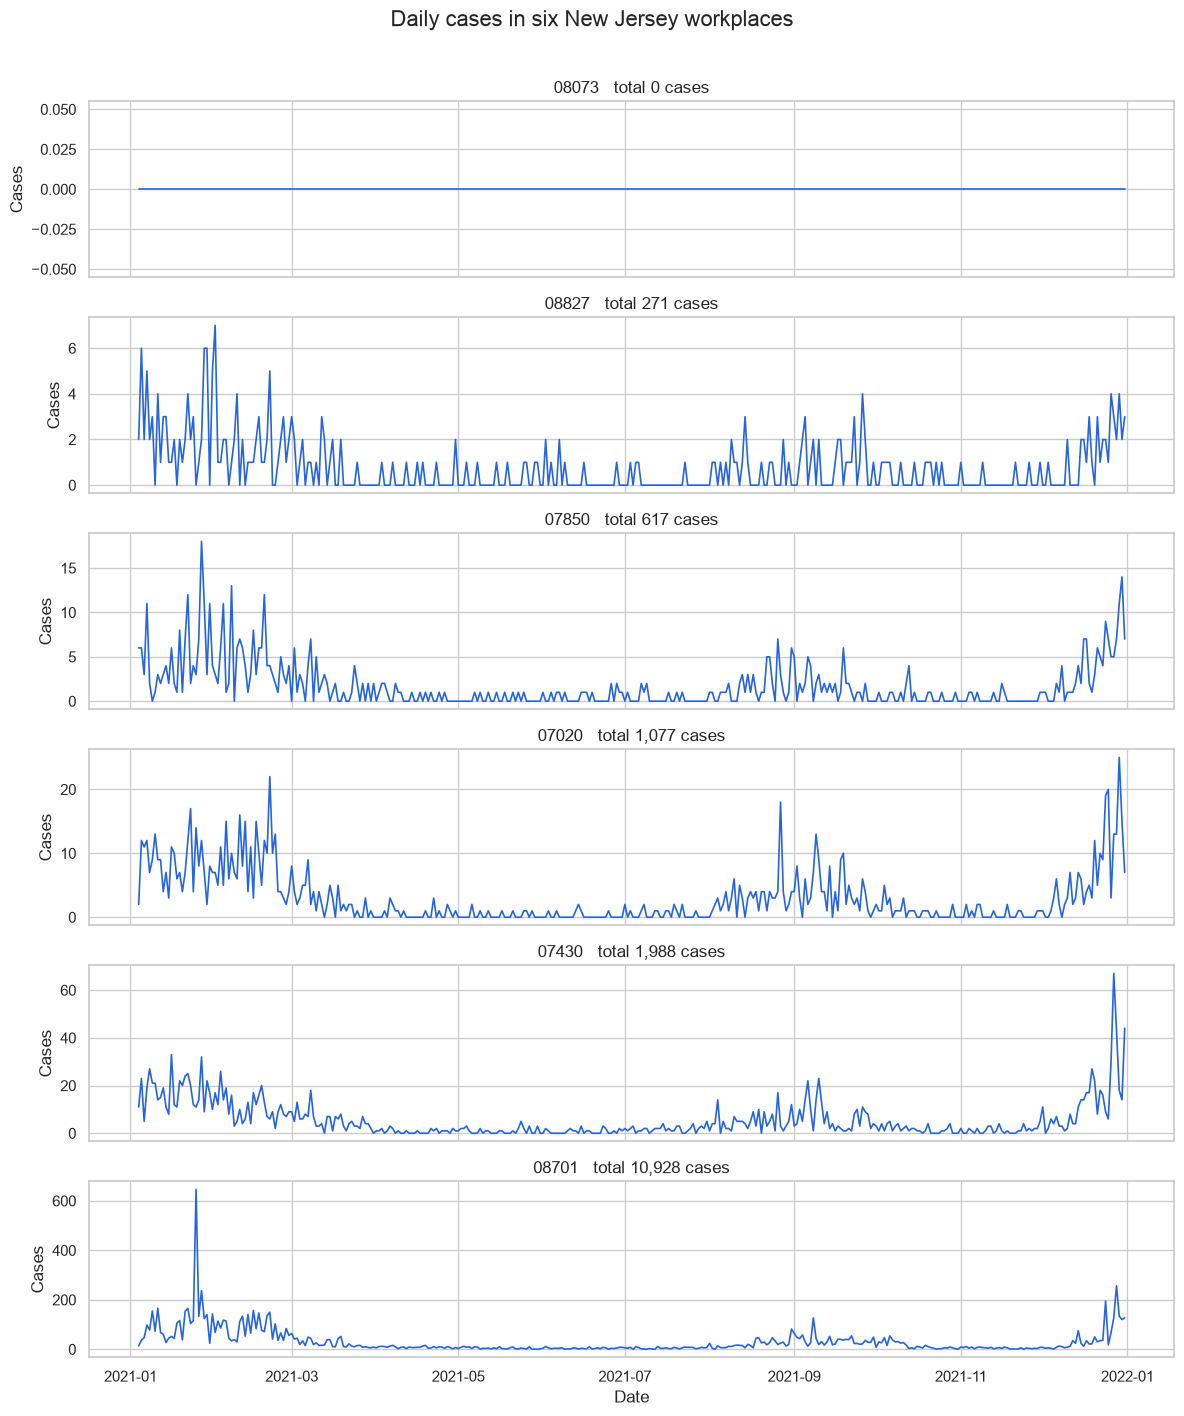

In [6]:
fig, axes = plt.subplots(6, 1, figsize=(12, 14), sharex=True)
for ax, zipcode in zip(axes, picks.index):
    one = sample.loc[sample.zipcode.eq(zipcode)]
    ax.plot(one.date, one.daily_cases, color="#2563EB", linewidth=1.2)
    ax.set_ylabel("Cases")
    ax.set_title(f"{zipcode}   total {int(picks.loc[zipcode]):,} cases")
axes[-1].set_xlabel("Date")
fig.suptitle("Daily cases in six New Jersey workplaces", y=1.01, fontsize=16)
fig.tight_layout()
plt.show()


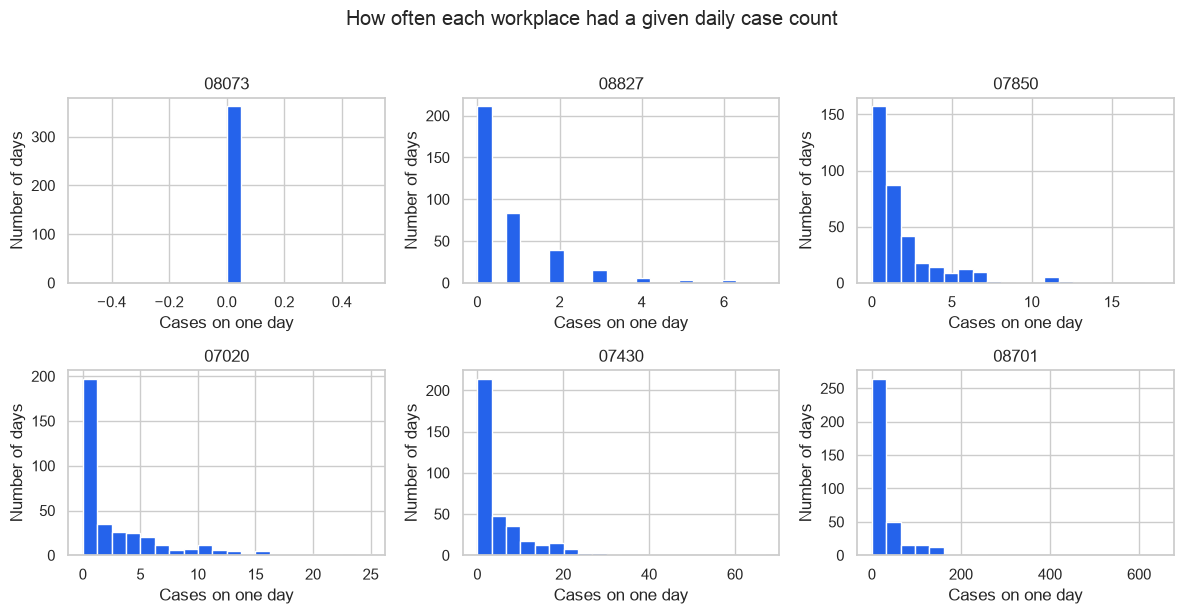

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, zipcode in zip(axes.ravel(), picks.index):
    one = sample.loc[sample.zipcode.eq(zipcode), "daily_cases"]
    ax.hist(one, bins=20, color="#2563EB", edgecolor="white")
    ax.set_title(zipcode)
    ax.set_xlabel("Cases on one day")
    ax.set_ylabel("Number of days")
fig.suptitle("How often each workplace had a given daily case count", y=1.02)
fig.tight_layout()
plt.show()


## 5. Local cases next to commute pressure

`daily_cases` is sickness **in** the workplace ZIP code. `pressure` is sickness **commuting in**, weighted by the 2021 job shares. They can rise together without being the same number.


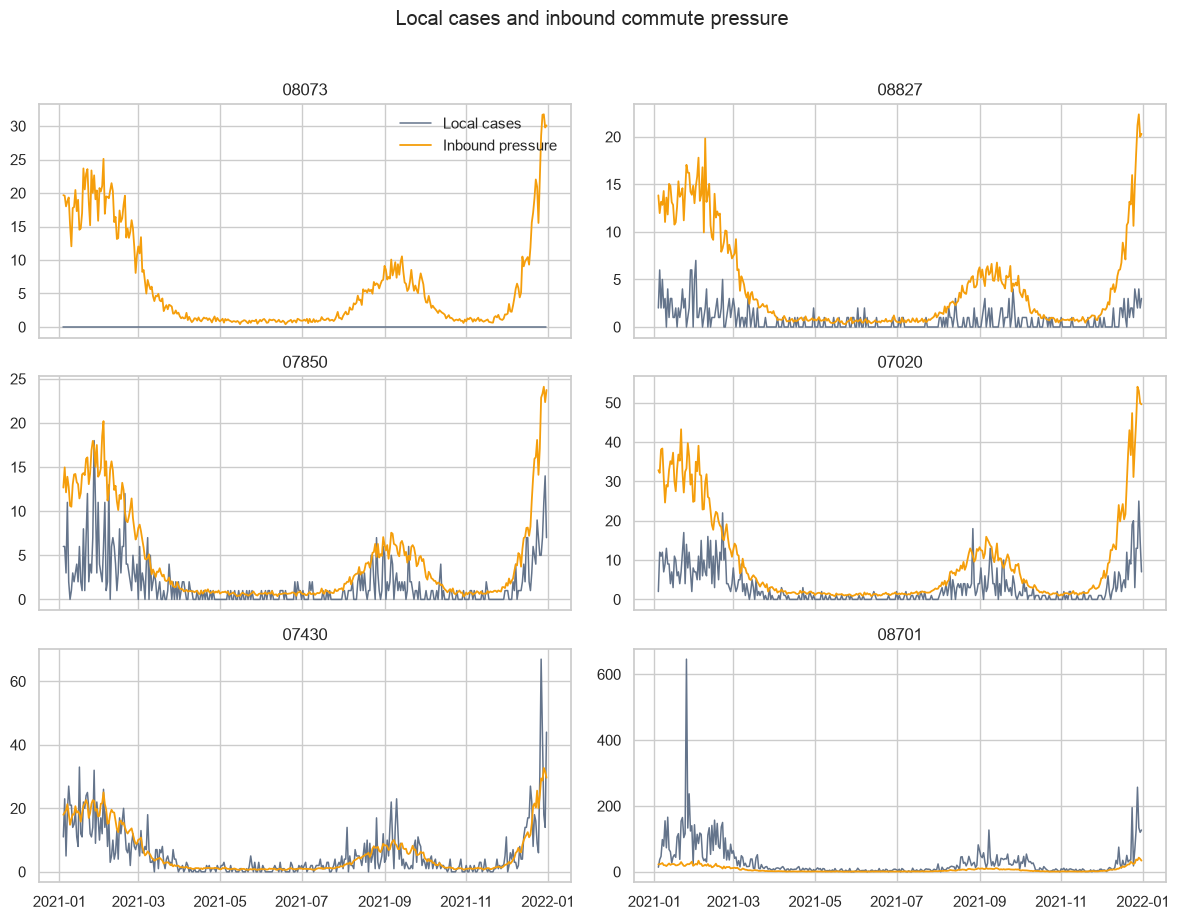

In [8]:
fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharex=True)
for ax, zipcode in zip(axes.ravel(), picks.index):
    one = sample.loc[sample.zipcode.eq(zipcode)]
    ax.plot(one.date, one.daily_cases, color="#64748B", linewidth=1.1, label="Local cases")
    ax.plot(one.date, one.pressure, color="#F59E0B", linewidth=1.3, label="Inbound pressure")
    ax.set_title(zipcode)
axes.ravel()[0].legend(frameon=False, loc="upper right")
fig.suptitle("Local cases and inbound commute pressure", y=1.02)
fig.tight_layout()
plt.show()


## 6. All workplaces together

The first histogram is every workplace-day. Most days are small. A few days are large, which is the January and December waves.

The second chart adds cases across all 590 workplaces, so the shared 2021 shape is easy to see.


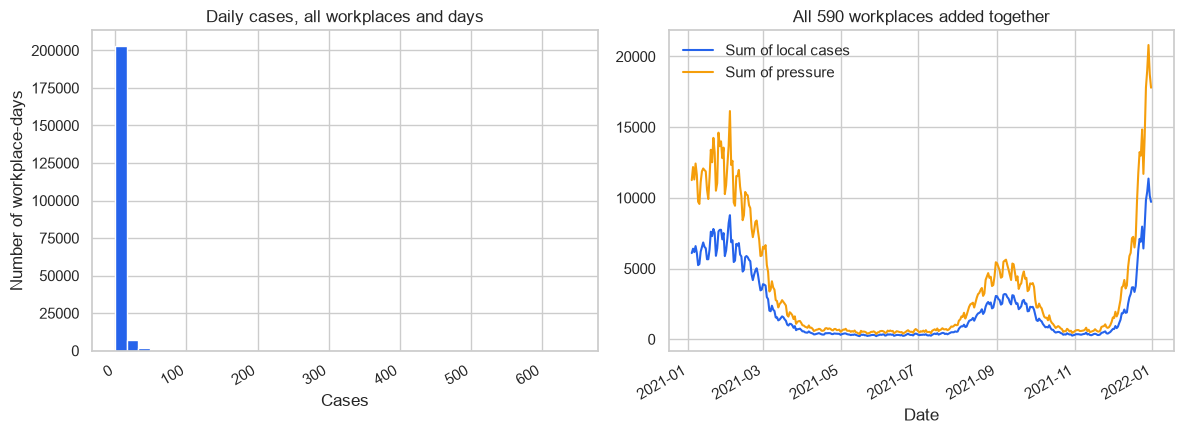

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(panel.daily_cases, bins=40, color="#2563EB", edgecolor="white")
axes[0].set_title("Daily cases, all workplaces and days")
axes[0].set_xlabel("Cases")
axes[0].set_ylabel("Number of workplace-days")

statewide = panel.groupby("date")[["daily_cases", "pressure"]].sum()
axes[1].plot(statewide.index, statewide.daily_cases, color="#2563EB", label="Sum of local cases")
axes[1].plot(statewide.index, statewide.pressure, color="#F59E0B", label="Sum of pressure")
axes[1].set_title("All 590 workplaces added together")
axes[1].set_xlabel("Date")
axes[1].legend(frameon=False)
fig.autofmt_xdate(rotation=30)
fig.tight_layout()
plt.show()


## 7. Changes from yesterday

`velocity` is positive when cases rose and negative when they fell. The series starts on 4 January, after the three blank startup days were removed.


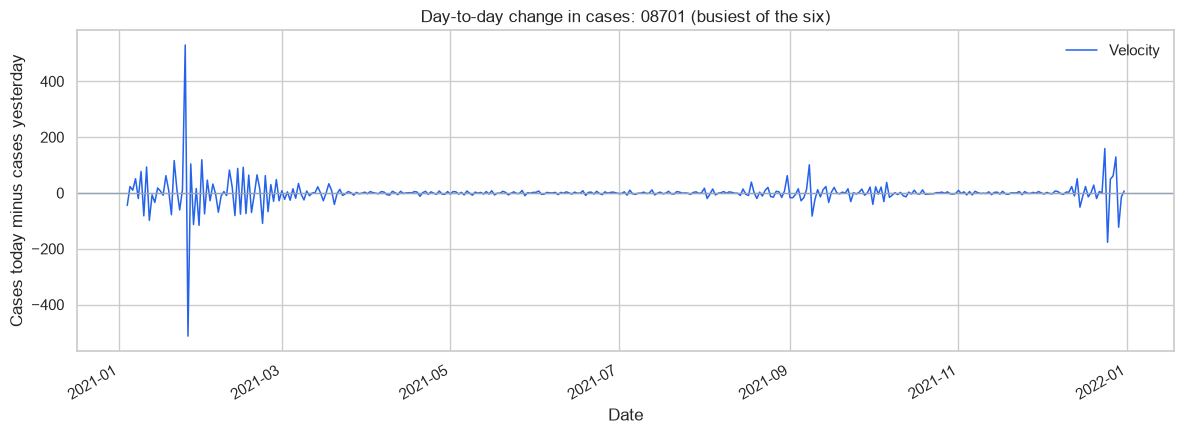

In [10]:
one = panel.loc[panel.zipcode.eq(picks.index[-1])]
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(one.date, one.velocity, color="#2563EB", linewidth=1.1, label="Velocity")
ax.axhline(0, color="#94A3B8", linewidth=1)
ax.set_title(f"Day-to-day change in cases: {picks.index[-1]} (busiest of the six)")
ax.set_ylabel("Cases today minus cases yesterday")
ax.set_xlabel("Date")
ax.legend(frameon=False)
fig.autofmt_xdate(rotation=30)
fig.tight_layout()
plt.show()
